<a href="https://colab.research.google.com/github/rafaelpimentacruz-stack/python_sis_26_2/blob/main/Jorge_Cruz_Aula12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Atividade sala 1
#Etapa 1
!pip install openpyxl

# =====================================================================
# ETAPA 1: Importações seguindo a PEP 8 e Criação da Planilha
# =====================================================================
import openpyxl
from openpyxl.styles import Font, PatternFill

# ---------------------------------------------------------------------
# PREPARAÇÃO: Gera um arquivo log.txt simulado para teste no Colab
# (Se você já subiu o seu log.txt na pasta lateral, pode apagar este bloco)
# ---------------------------------------------------------------------
conteudo_log = """2026-11-26 08:00:12 - INFO - Sistema de monitoramento iniciado
2026-11-26 08:45:30 - INFO - Backup diario concluido sem falhas
2026-11-26 09:12:05 - AVISO - Uso de disco no srv-db-01 atingiu 88%
2026-11-26 10:03:44 - ERRO - Timeout de conexao no srv-backup-01
2026-11-26 11:20:10 - INFO - Servicos reiniciados pelo administrador
"""
with open("log.txt", "w", encoding="utf-8") as arq_teste:
    arq_teste.write(conteudo_log)

# Criando a pasta de trabalho e a primeira aba ("Servidores")
wb = openpyxl.Workbook()
ws_servidores = wb.active
ws_servidores.title = "Servidores"

cabecalho_servidores = [
    "Hostname",
    "IP",
    "Memória (GB)",
    "Uso de Disco (%)",
    "Status",
]
ws_servidores.append(cabecalho_servidores)

for celula in ws_servidores[1]:
    celula.font = Font(bold=True)

# Inserindo os dados simulados dos servidores
dados_servidores = [
    ["srv-web-01", "192.168.10.11", 16, 45, "Ativo"],
    ["srv-db-01", "192.168.10.12", 64, 88, "Ativo"],
    ["srv-cache-01", "192.168.10.13", 32, 62, "Ativo"],
    ["srv-backup-01", "192.168.10.14", 32, 94, "Alerta"],
    ["srv-dev-01", "192.168.10.15", 8, 25, "Inativo"],
]

for srv in dados_servidores:
    ws_servidores.append(srv)


# =====================================================================
# ETAPA 2: Edição (Verificação de Disco >= 80% e Alerta Visual/Terminal)
# =====================================================================
fundo_alerta = PatternFill(
    start_color="FFCCCC", end_color="FFCCCC", fill_type="solid"
)
fonte_alerta = Font(color="9C0006", bold=True)

print("--- Auditoria de Armazenamento dos Servidores ---")

for linha in range(2, ws_servidores.max_row + 1):
    hostname = ws_servidores.cell(row=linha, column=1).value
    celula_disco = ws_servidores.cell(row=linha, column=4)
    uso_disco = celula_disco.value

    if uso_disco >= 80:
        # Pinta a célula de vermelho claro e destaca o texto
        celula_disco.fill = fundo_alerta
        celula_disco.font = fonte_alerta

        # Exibe o alerta no terminal
        print(
            f"ALERTA: O servidor '{hostname}' está com {uso_disco}% de uso "
            "de disco e precisa de expansão de armazenamento!"
        )


# =====================================================================
# ETAPA 3: Abertura, Extração do Log e Criação da Segunda Aba
# =====================================================================
ws_logs = wb.create_sheet(title="Auditoria de Logs")

cabecalho_logs = ["Data/Hora", "Tipo de Evento", "Mensagem"]
ws_logs.append(cabecalho_logs)

for celula in ws_logs[1]:
    celula.font = Font(bold=True)

print("\n--- Processando Arquivo de Log ---")

try:
    with open("log.txt", "r", encoding="utf-8") as arquivo_log:
        for linha in arquivo_log:
            linha_limpa = linha.strip()

            if not linha_limpa:
                continue

            # Divide a linha em: [Data/Hora, Tipo de Evento, Mensagem]
            partes = linha_limpa.split(" - ", maxsplit=2)

            if len(partes) == 3:
                data_hora = partes[0].strip()
                tipo_evento = partes[1].strip()  # INFO, AVISO ou ERRO
                mensagem = partes[2].strip()
            else:
                # Plano B caso alguma linha do log não use " - " como separador
                data_hora = "N/A"
                tipo_evento = "DESCONHECIDO"
                for nivel in ["INFO", "AVISO", "ERRO"]:
                    if nivel in linha_limpa.upper():
                        tipo_evento = nivel
                        break
                mensagem = linha_limpa

            ws_logs.append([data_hora, tipo_evento, mensagem])

    print("Logs extraídos e inseridos na aba 'Auditoria de Logs' com sucesso.")

except FileNotFoundError:
    print(
        "Erro: O arquivo 'log.txt' não foi encontrado. "
        "Verifique se ele foi enviado para a pasta do Google Colab."
    )

# Salvando o arquivo final consolidado no diretório de execução
arquivo_final = "auditoria_mensal_ti.xlsx"
wb.save(arquivo_final)
print(f"\nRotina finalizada! Planilha '{arquivo_final}' salva com sucesso.")

In [ ]:
#Atividade sala 2

!pip install psutil


# =====================================================================
# ETAPA 1: Importações (PEP 8)
# =====================================================================
import time

import psutil

# =====================================================================
# ETAPA 3: Definição do caminho e gravação explícita do cabeçalho
# =====================================================================
arquivo_csv = "telemetria_sistema.csv"

with open(arquivo_csv, "w", encoding="utf-8") as arq:
    arq.write("Iteracao,Uso_CPU_Pct,Uso_RAM_Pct\n")

print(f"Arquivo '{arquivo_csv}' inicializado. Iniciando coleta...\n")

# =====================================================================
# ETAPAS 1, 2 e 4: Ciclo de 5 capturas com pausa de 1s e gravação incremental ('a')
# =====================================================================
for iteracao in range(1, 6):
    # Captura instantânea de CPU (%) e Memória RAM (%)
    uso_cpu = psutil.cpu_percent(interval=None)
    uso_ram = psutil.virtual_memory().percent

    # Formata a linha de telemetria
    linha_dados = f"{iteracao},{uso_cpu},{uso_ram}\n"

    # Persistência incremental no modo append ('a')
    with open(arquivo_csv, "a", encoding="utf-8") as arq:
        arq.write(linha_dados)

    print(
        f"Iteração {iteracao}/5 -> CPU: {uso_cpu}% | RAM: {uso_ram}% "
        "(gravado no CSV)"
    )

    # Pausa de 1 segundo entre as capturas (evita esperar após a última)
    if iteracao < 5:
        time.sleep(1)

print(f"\nColeta concluída com sucesso! Dados salvos em '{arquivo_csv}'.")

Arquivo 'telemetria_sistema.csv' inicializado. Iniciando coleta...

Iteração 1/5 -> CPU: 18.9% | RAM: 9.7% (gravado no CSV)
Iteração 2/5 -> CPU: 3.0% | RAM: 9.7% (gravado no CSV)
Iteração 3/5 -> CPU: 2.0% | RAM: 9.7% (gravado no CSV)
Iteração 4/5 -> CPU: 2.5% | RAM: 9.7% (gravado no CSV)
Iteração 5/5 -> CPU: 2.5% | RAM: 9.7% (gravado no CSV)

Coleta concluída com sucesso! Dados salvos em 'telemetria_sistema.csv'.


--- Dados Carregados ---
   Iteracao  Uso_CPU_Pct  Uso_RAM_Pct
0         1         18.9          9.7
1         2          3.0          9.7
2         3          2.0          9.7
3         4          2.5          9.7
4         5          2.5          9.7 

--- Resumo Descritivo de Consumo de Hardware ---
Total de amostras analisadas : 5
Média aritmética de CPU      : 5.78%
Média aritmética de RAM      : 9.70%
Pico máximo de CPU           : 18.90%
Pico máximo de RAM           : 9.70%



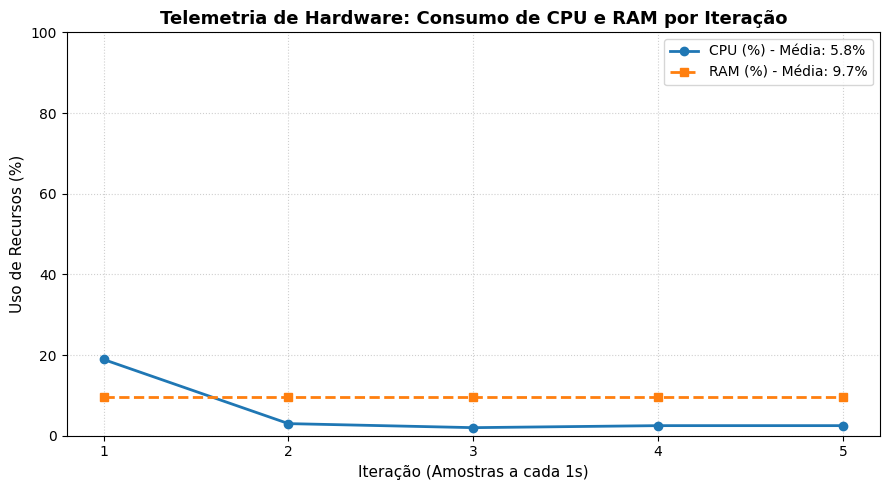

In [ ]:
#Atividade sala 3
# =====================================================================
# ETAPA 1: Importações (PEP 8) e Ingestão do CSV com Pandas
# =====================================================================
import matplotlib.pyplot as plt
import pandas as pd

arquivo_csv = "telemetria_sistema.csv"
df = pd.read_csv(arquivo_csv)

print("--- Dados Carregados ---")
print(df, "\n")


# =====================================================================
# ETAPA 2: Cálculo das Médias Aritméticas e Resumo Descritivo
# =====================================================================
media_cpu = df["Uso_CPU_Pct"].mean()
media_ram = df["Uso_RAM_Pct"].mean()

print("--- Resumo Descritivo de Consumo de Hardware ---")
print(f"Total de amostras analisadas : {len(df)}")
print(f"Média aritmética de CPU      : {media_cpu:.2f}%")
print(f"Média aritmética de RAM      : {media_ram:.2f}%")
print(f"Pico máximo de CPU           : {df['Uso_CPU_Pct'].max():.2f}%")
print(f"Pico máximo de RAM           : {df['Uso_RAM_Pct'].max():.2f}%\n")


# =====================================================================
# ETAPA 3: Gráfico de Linha com Matplotlib (Variação de CPU e RAM)
# =====================================================================
plt.figure(figsize=(9, 5))

# Linha da CPU
plt.plot(
    df["Iteracao"],
    df["Uso_CPU_Pct"],
    marker="o",
    linestyle="-",
    linewidth=2,
    color="#1f77b4",
    label=f"CPU (%) - Média: {media_cpu:.1f}%",
)

# Linha da Memória RAM
plt.plot(
    df["Iteracao"],
    df["Uso_RAM_Pct"],
    marker="s",
    linestyle="--",
    linewidth=2,
    color="#ff7f0e",
    label=f"RAM (%) - Média: {media_ram:.1f}%",
)

# Configurações visuais do gráfico
plt.title("Telemetria de Hardware: Consumo de CPU e RAM por Iteração", fontsize=13, fontweight="bold")
plt.xlabel("Iteração (Amostras a cada 1s)", fontsize=11)
plt.ylabel("Uso de Recursos (%)", fontsize=11)
plt.xticks(df["Iteracao"])  # Garante que o eixo X exiba números inteiros (1, 2, 3, 4, 5)
plt.ylim(0, 100)            # Fixa a escala percentual de 0% a 100%
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="best")

plt.tight_layout()
plt.show()